In [330]:
import torch

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(torch.cuda.current_device())
    print(torch.cuda.device_count())
    print(torch.cuda.get_device_name(0))

device

0
1
NVIDIA GeForce MX550


device(type='cuda', index=0)

# Simulation of Multivariate Normal Distribution


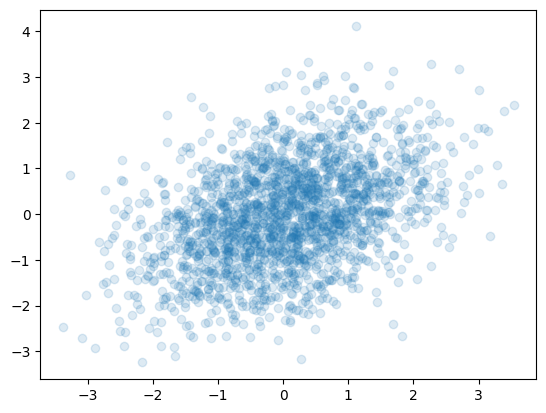

In [331]:
import matplotlib.pyplot as plt

mean_A = torch.tensor([-0.5, -0.5])
covariance_A = torch.tensor([[1, 0.25], [0.25, 1]])

mean_B = torch.tensor([0.5, 0.5])
covariance_B = torch.tensor([[1, 0.25], [0.25, 1]])

m = 1000

dist_A = torch.distributions.MultivariateNormal(mean_A, covariance_A)
dist_B = torch.distributions.MultivariateNormal(mean_B, covariance_B)

samples_A = dist_A.sample((m,))
samples_B = dist_B.sample((m,))

x = torch.cat((samples_A, samples_B), dim=0)
x_np = x.numpy()
plt.scatter(x_np[:, 0], x_np[:, 1], alpha=0.15)
plt.show()


# K-mean Clustering

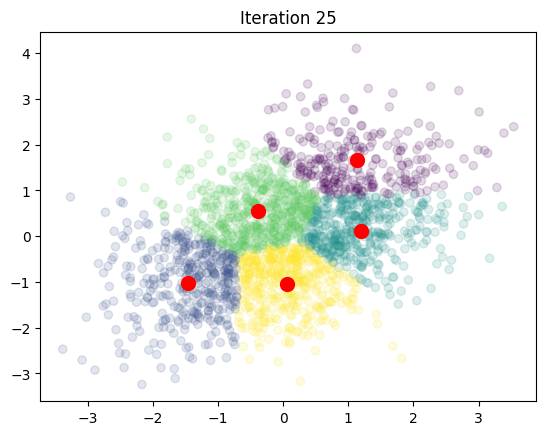

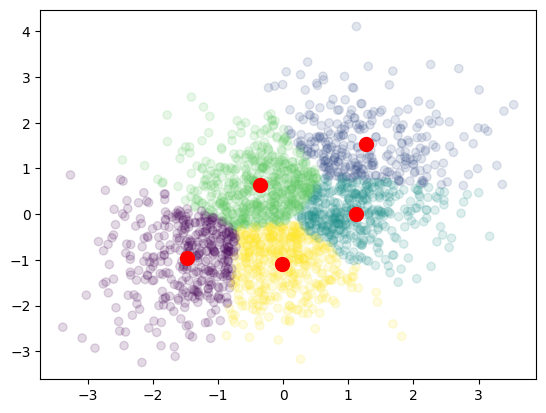

In [332]:
from IPython.display import clear_output
# Scale Data
#x = ((x-x.min()) / (x.max()-x.min())) * 9 +1
k = 5
max_iter = 1000

def random_centroids(x, k):
    indices = torch.randperm(x.size(0))[:k]
    centroids = x[indices]
    return centroids

def assign_clusters(x, centroids):
    distances = torch.cdist(x, centroids)
    distances = distances.min(dim=1)
    clusters = distances.indices
    return clusters


def plot_clusters(x, clusters, centroids, iteration = 0):
    x_clusters = x.clone()
    x_clusters = x_clusters.view(-1, 2)
    x_clusters = torch.cat((x_clusters, clusters.unsqueeze(1).float()), dim=1)
    clear_output(wait=True)
    plt.scatter(x_clusters[:, 0], x_clusters[:, 1], c=x_clusters[:, 2], alpha=0.15)
    plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=100)
    plt.title(f"Iteration {iteration}")
    plt.show()

def update_centroids(x, clusters, k):
    centroids = torch.zeros(k, 2)
    for i in range(k):
        mask = clusters == i
        cluster_points = x[mask]
        centroids[i] = cluster_points.mean(dim=0)
    return centroids


#Random Centroids
centroids = random_centroids(x, k)
#Assign Clusters
clusters = assign_clusters(x, centroids)
#Plot Clusters
plot_clusters(x, clusters, centroids)

for i in range(max_iter):
    old_centroids = torch.clone(centroids)
    centroids = update_centroids(x, clusters, k)
    if torch.all(centroids == old_centroids):
        break
    clusters = assign_clusters(x, centroids)
    plot_clusters(x, clusters, centroids, i)
    

#Compare with sklearn
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=k)
kmeans.fit(x)
centroids = kmeans.cluster_centers_
clusters = kmeans.labels_

plt.scatter(x_np[:, 0], x_np[:, 1], c=clusters, alpha=0.15)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=100)
plt.show()


# Projection with Principal Components Analysis (PCA)

In [336]:
x = torch.randn(100, 4)
x


tensor([[ 9.4800e-01,  1.8835e+00,  9.1368e-01, -6.8043e-03],
        [ 1.1672e+00, -1.1819e+00,  4.6884e-02,  1.5805e-01],
        [ 4.2663e-01,  5.4466e-01, -2.0283e+00,  4.5026e-02],
        [-1.2034e+00, -7.2574e-01,  1.8381e-01, -2.2732e-02],
        [ 3.1565e-01, -1.6106e+00,  1.1853e+00,  4.1829e-01],
        [ 8.7486e-01,  1.6339e+00, -7.4867e-01, -3.4473e-01],
        [ 2.3540e+00, -1.4006e+00, -5.9538e-01, -1.4077e+00],
        [-1.6752e-01,  1.0299e+00,  1.1215e+00, -3.4629e-01],
        [ 2.6387e+00, -3.1931e-01,  1.1033e+00,  1.1901e+00],
        [ 1.9117e+00,  7.7531e-01,  1.0841e+00,  5.1039e-01],
        [ 1.1621e+00, -3.6341e-01, -8.9912e-01, -4.4716e-01],
        [ 5.3364e-01, -4.5789e-01, -1.7548e+00, -7.6331e-01],
        [ 4.4573e-01, -5.7362e-01,  9.6608e-01, -9.5381e-01],
        [ 3.2522e-01,  1.4726e+00, -6.2891e-01, -8.5404e-01],
        [-7.4496e-01, -1.3248e+00, -7.7193e-01,  6.7717e-01],
        [ 1.5564e+00,  1.6794e+00,  1.1128e+00,  3.9481e-01],
        